# 05 Tool (layer 5)

What an officer and the field staff touch. It keeps the old three-step flow (event, unit calls,
evidence card) and changes the card: it shows the **call**, **P_u** and the **number of checks**, and it
has no abstain state. Every unit is answered; P_u says how far to trust the answer.

Steps
1. Inputs: files from `artifacts/layer1` to `layer4`, with a documented synthetic fixture for every
   part that is not there yet. The provenance table below says, part by part, what is real.
2. Event board: region, event, satellite scenes.
3. Unit calls: ranked table (most likely wrong first) and map.
4. Evidence card with scene IDs, dates and a receipt hash that can be re-derived.
5. Officer day-route view, flooded roads in blue.
6. Offline field-check entry, sync, live update of the call.
7. Farmer-report intake and claim cross-check against the unit call.
8. The interactive wizard (ipywidgets) with a static fallback that renders under nbconvert.
9. Artifacts in `artifacts/layer5/` and the final checks.

Formulas used here (from layer 3): theta_u = sum_h W_uh p_uh, p_uh = (k_uh + m pi_h)/(n_uh + m),
call_u = [theta_u > tau], P_u = Phi((theta_u - tau)/s_u), tau = 0.25. P(call right) = P_u if the call is
above, else 1 - P_u.

This layer fits nothing, so there is no train or test split here; the only number checked at the end is
structural (every unit has a call, every receipt re-derives).

In [1]:
%matplotlib inline
import json, hashlib, pathlib, platform
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image

from paddybird import intake as I, card as C, views as V

ROOT = pathlib.Path.cwd()
if not (ROOT / "paddybird").exists():
    ROOT = ROOT / "notebooks"
ART = ROOT / "artifacts"
OUT = ART / "layer5"
OUT.mkdir(parents=True, exist_ok=True)
SEED, TAU = 0, I.TAU
np.random.seed(SEED)
print("python", platform.python_version(), "numpy", np.__version__, "pandas", pd.__version__, "matplotlib", matplotlib.__version__)

python 3.11.9 numpy 2.4.6 pandas 3.1.1 matplotlib 3.11.2


## 1 Inputs and provenance

`I.load_inputs` reads the layer contract (files only). For each part (units and their estimates,
scenes, roads, routes, completed checks) it uses the real artifact when one with the expected columns
exists and otherwise the fixture from `I.make_fixture` (its docstring is the full specification: 12
invented units, two map strata, prior pi_h = (0.08, 0.75), m = 10, a 9 x 7 road lattice, scene IDs that
start with `SYNTH_`).

In [2]:
inp = I.load_inputs(ART, seed=SEED)
prov = pd.DataFrame([{"part": k, "source": v} for k, v in inp.provenance.items()])
display(prov)
print("layer manifests found:", sorted(inp.manifests) or "none")
REAL = {k: v.startswith("real") for k, v in inp.provenance.items() if not k.endswith(" says")}
print(f"units {len(inp.units)}, scenes {len(inp.scenes)}, road nodes {len(inp.roads_nodes)}, road segments {len(inp.roads_edges)}, "
      f"routes {len(inp.routes)}, completed checks {len(inp.checks)}")

,part,source
0,units,real: artifacts/layer3/unit_calls.csv
1,roads,fixture lattice over the unit layout (flooded ...
2,routes,fixture planner over fixture lattice (layer-4 ...
3,scenes,real: artifacts/layer1/receipts/layer1_build.json
4,checks,none (no layer-4 checks table)
5,unit layout,schematic grid (units are scattered clusters; ...
6,layer1 says,"chips: sen1floods11, roads: osm-overpass, revi..."
7,layer2 says,layer1
8,layer3 says,real layer 2 artifacts (artifacts/layer2/maps ...
9,layer4 says,layer1 roads and units (Godavari delta block (...


layer manifests found: ['layer1', 'layer2', 'layer3', 'layer4']
units 34, scenes 14, road nodes 64, road segments 112, routes 2, completed checks 0


## 2 Step 1: event board

Which place, which flood, which satellite passes. In the old tool this was the question box; here
the officer starts from the event.

In [3]:
sc = pd.DataFrame(inp.scenes)
event_html = (f"<p><b>{inp.region['name']}</b>, {inp.region.get('event', '')}. "
              f"{len(inp.units)} units, loss line {TAU:.0%}.</p>")
l1 = inp.region.get("layer1_region")
if l1:
    event_html += (f"<p>Layer 1 region: <b>{l1.get('name')}</b>, season {' to '.join(l1.get('season', []))}"
                   f" ({l1.get('note', '')}). The scenes below are layer 1's passes for this region.</p>")
event_html += sc.to_html(index=False, border=0)
display(HTML(event_html))

id,date,sensor
S1A_IW_GRDH_1SDV_20221025T002301_20221025T002327_045591_05737D,2022-10-25,
S1A_IW_GRDH_1SDV_20221013T002301_20221013T002327_045416_056E53,2022-10-13,
S1A_IW_GRDH_1SDV_20221001T002301_20221001T002327_045241_05686C,2022-10-01,
S1A_IW_GRDH_1SDV_20220919T002300_20220919T002326_045066_056290,2022-09-19,
S1A_IW_GRDH_1SDV_20220907T002301_20220907T002326_044891_055CB2,2022-09-07,
S1A_IW_GRDH_1SDV_20220826T002300_20220826T002326_044716_0556C3,2022-08-26,
S1A_IW_GRDH_1SDV_20220814T002259_20220814T002325_044541_0550DE,2022-08-14,
S1A_IW_GRDH_1SDV_20220802T002258_20220802T002324_044366_054B71,2022-08-02,
S1A_IW_GRDH_1SDV_20220721T002258_20220721T002324_044191_05464D,2022-07-21,
S1A_IW_GRDH_1SDV_20220716T124350_20220716T124419_044126_05445C,2022-07-16,


## 3 Step 2: unit calls

Every unit has a call; there is no undecided row. The table is ordered by the chance the call is
wrong, min(P_u, 1 - P_u), so the top rows are where a field check helps most. On the map, colour is the
call and the shade is the probability the call is right.

rank,unit_id,name,theta,s,call,P_u,p_call_right,n_checks,p_wrong
1,India_747992_u01,India_747992_u01,24.5%,0.193,below,0.490,0.510,0,0.490
2,India_747992_u10,India_747992_u10,32.6%,0.218,above,0.637,0.637,0,0.363
3,India_900498_u10,India_900498_u10,16.6%,0.116,below,0.234,0.766,0,0.234
4,India_747992_u00,India_747992_u00,45.8%,0.269,above,0.781,0.781,0,0.219
5,India_804466_u11,India_804466_u11,5.7%,0.138,below,0.081,0.919,0,0.081
6,India_747992_u11,India_747992_u11,10.0%,0.101,below,0.070,0.930,0,0.070
7,India_943439_u11,India_943439_u11,10.1%,0.091,below,0.050,0.950,0,0.050
8,India_943439_u10,India_943439_u10,11.3%,0.081,below,0.046,0.954,0,0.046
9,India_1050276_u00,India_1050276_u00,4.4%,0.093,below,0.013,0.987,0,0.013
10,India_1072277_u10,India_1072277_u10,3.3%,0.094,below,0.010,0.990,0,0.010


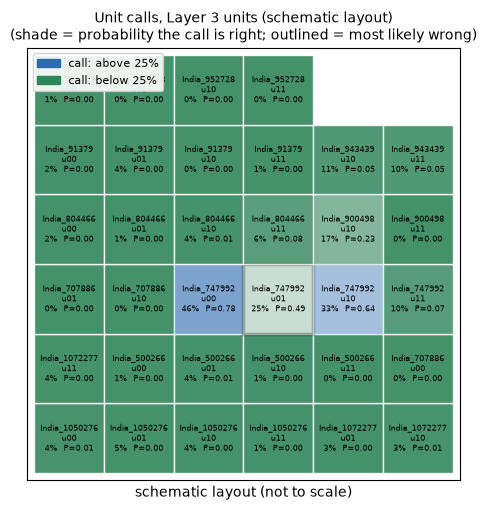

calls above: 2  below: 32  expected wrong calls: 1.6


In [4]:
table = V.unit_calls_table(inp.units, TAU)
display(HTML(V.table_html(table)))
fig, ax = plt.subplots(figsize=(6.6, 5.2))
V.plot_unit_map(inp.units, ax, tau=TAU, highlight=table.unit_id.iloc[0],
                title=f"Unit calls, {inp.region['name']}\n(shade = probability the call is right; outlined = most likely wrong)")
fig.tight_layout(); fig.savefig(OUT / "unit_map.png", dpi=150); plt.show()
print("calls above:", int((table.call == "above").sum()), " below:", int((table.call == "below").sum()),
      " expected wrong calls:", round(float(table.p_wrong.sum()), 2))

The same calls on a Leaflet map (folium), as in the old web UI. Base tiles load only in a browser
with a network; the unit overlays and flooded roads are embedded in `unit_map.html`.

In [5]:
try:
    if "schematic" in inp.units and inp.units.schematic.any():
        raise ValueError("units have no single-region coordinates (schematic layout), so a web map would mislead")
    fmap = V.folium_map(inp.units, TAU, inp.roads_edges, inp.roads_nodes)
    fmap.save(str(OUT / "unit_map.html"))
    print("wrote", (OUT / "unit_map.html").relative_to(ROOT))
except Exception as exc:          # folium is optional; the matplotlib map above carries the same content
    fmap = None
    (OUT / "unit_map.html").unlink(missing_ok=True)          # never leave a stale map from an earlier run
    print("folium map skipped:", exc)

folium map skipped: units have no single-region coordinates (schematic layout), so a web map would mislead


## 4 Step 3: evidence card

The card for the unit whose call is most likely wrong. It states the call, P_u, the probability the
call is right, the number of checks, the scenes (IDs and dates) and a receipt. The receipt is
canonical JSON of the inputs and outputs with a SHA-256 hash, adapted from the old Paddybird receipt;
`C.verify_receipt` re-derives both hashes.

In [6]:
def checks_of(uid, checks):
    return checks[checks.unit_id == uid].to_dict("records") if len(checks) else []

def make_card(uid, units=None, checks=None, tau=TAU):
    units = inp.units if units is None else units
    checks = inp.checks if checks is None else checks
    row = V.at_tau(units, tau).set_index("unit_id").loc[uid].to_dict()
    row["unit_id"] = uid
    return C.build_card(row, inp.scenes, checks_of(uid, checks), tau=tau,
                        params={"m": I.M_SHRINK, "pi_h": list(I.PRIOR_PI)}, sources=inp.provenance)

focus = table.unit_id.iloc[0]
card0 = make_card(focus)
display(HTML(C.card_html(card0)))
print(C.card_text(card0))
print("receipt verifies:", C.verify_receipt(card0["receipt"]))

[BELOW 25%] India_747992_u01: flooded paddy share 24.5% (95% range 0.0% to 62.3%). Call: below the 25% loss line. Probability the call is right: 0.51.
  P_u = 0.490, checks = 0
  scene 2022-06-03 S1A_IW_GRDH_1SDV_20220603T002251_20220603T002321_043491_053160
  scene 2022-06-15 S1A_IW_GRDH_1SDV_20220615T002252_20220615T002321_043666_05369A
  scene 2022-06-27 S1A_IW_GRDH_1SDV_20220627T002253_20220627T002322_043841_053BDB
  scene 2022-07-09 S1A_IW_GRDH_1SDV_20220709T002253_20220709T002323_044016_054109
  scene 2022-07-16 S1A_IW_GRDH_1SDV_20220716T124350_20220716T124419_044126_05445C
  scene 2022-07-21 S1A_IW_GRDH_1SDV_20220721T002258_20220721T002324_044191_05464D
  scene 2022-08-02 S1A_IW_GRDH_1SDV_20220802T002258_20220802T002324_044366_054B71
  scene 2022-08-14 S1A_IW_GRDH_1SDV_20220814T002259_20220814T002325_044541_0550DE
  scene 2022-08-26 S1A_IW_GRDH_1SDV_20220826T002300_20220826T002326_044716_0556C3
  scene 2022-09-07 S1A_IW_GRDH_1SDV_20220907T002301_20220907T002326_044891_055CB2
  s

## 5 Officer day-route view

The day's routes, one colour per officer, over the road graph with flooded roads in blue. Village
dots are shaded by the chance their call is wrong (the value of a visit). When layer 4 has written
`routes_day1.json` the routes come from there; the fixture uses a small cheapest-insertion planner
(gain per extra minute on the flood-aware graph) only so the view has something to draw.

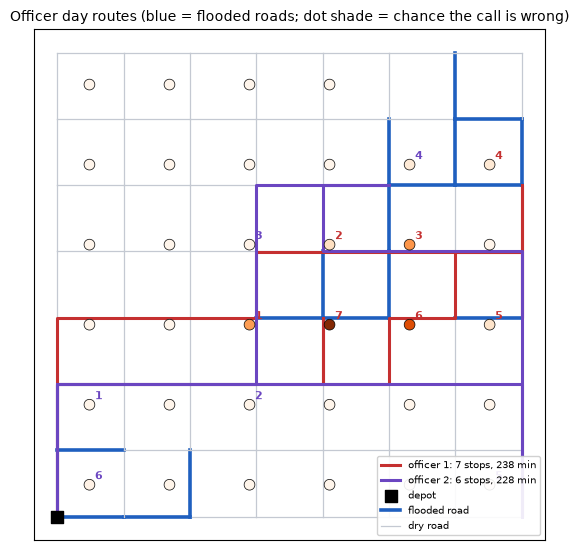

officer 1: stops India_747992_u00 > India_804466_u11 > India_900498_u10 > India_943439_u11 > India_747992_u11 > India_747992_u10 > India_747992_u01, 238 min
officer 2: stops India_1072277_u11 > India_500266_u01 > India_804466_u10 > India_943439_u10 > India_1072277_u10 > India_1050276_u00, 228 min
flooded road segments: 17 of 112


In [7]:
fig, ax = plt.subplots(figsize=(6.6, 5.6))
V.plot_route_view(inp.roads_nodes, inp.roads_edges, inp.routes, inp.units, ax)
fig.tight_layout(); fig.savefig(OUT / "route_view.png", dpi=150); plt.show()
for r in inp.routes:
    print(f"{r['officer']}: stops {' > '.join(r['stops'])}" + (f", {r['minutes']:.0f} min" if r.get("minutes") else ""))
print("flooded road segments:", int(inp.roads_edges.flooded.sum()), "of", len(inp.roads_edges))

## 6 Offline field-check entry and live update

Field staff record checks on the phone with no network: each check is appended to a local JSONL
queue with its inclusion probability and an entry hash. On sync the queue is merged and duplicates (a
queue sent twice) are dropped by hash. The unit's estimate is then updated: the stratified form when
the strata are known, otherwise a Beta update of (theta_u, s_u). Each check is weighted by 1/pi.

The three entries below are **demonstration entries typed for this notebook**, not field data.

In [8]:
store = I.OfflineCheckStore(OUT / "field_checks_pending.jsonl")
store.clear()                                    # reproducible run: start with an empty queue
demo = [I.FieldCheck(unit_id=focus, plot_id=f"{focus}-P{j}", flooded=fl, officer="officer 1", stratum=h, pi=pi,
                     ts=f"2026-07-24T0{j}:30:00+00:00")
        for j, (fl, h, pi) in enumerate([(True, 1, 0.4), (True, 1, 0.4), (False, 0, 0.25)], start=1)]
recs = [store.add(c) for c in demo]
store.add(demo[0])                               # the same entry queued twice by a flaky phone
print("queued:", len(store.pending()), "entries (one duplicate)")
synced = store.sync(inp.checks)
new = synced.iloc[len(inp.checks):]
print("after sync:", len(new), "new checks for", sorted(new.unit_id.unique()))
units1 = I.apply_checks(inp.units, new, TAU)
cmp = pd.concat([inp.units.set_index("unit_id").loc[[focus], ["theta", "s", "call", "P_u", "n_checks"]].assign(when="before"),
                 units1.set_index("unit_id").loc[[focus], ["theta", "s", "call", "P_u", "n_checks"]].assign(when="after")])
display(cmp)
card1 = make_card(focus, units1, synced)
display(HTML(C.card_html(card1)))
table1 = V.unit_calls_table(units1, TAU)
print("expected wrong calls before", round(float(table.p_wrong.sum()), 3), "after", round(float(table1.p_wrong.sum()), 3))

queued: 4 entries (one duplicate)
after sync: 3 new checks for ['India_747992_u01']


,theta,s,call,P_u,n_checks,when
unit_id,,,,,,
India_747992_u01,0.245350,0.192700,below,0.490380,0,before
India_747992_u01,0.409844,0.159679,above,0.841595,3,after


expected wrong calls before 1.602 after 1.27


## 7 Farmer-report intake and claim cross-check

A farmer intimation is stored with the farmer reference hashed, the hours since the loss (PMFBY asks
for 72 hours) and a report hash. The cross-check compares the claim with the radar: the probability the
plot is flooded is, in order of preference, the layer-2 map probability at the plot, the checked rate
in the plot's map stratum (mapped dry or mapped flooded), or the unit's theta_u when the plot has no
location. Every report gets a lean (consistent or inconsistent with radar); a plot below about half a
hectare keeps its lean with low weight. The list orders inspections; it never rejects a claim, and
these self-selected reports do not enter theta_u.

The reports below are **invented examples**.

In [9]:
uids = list(table.unit_id)
reports = [I.FarmerReport(unit_id=uids[0], farmer_ref="farmer-A", plot_ha=1.2, loss_date="2026-07-20", reported_at="2026-07-21T10:00:00", map_stratum=1),
           I.FarmerReport(unit_id=uids[-1], farmer_ref="farmer-B", plot_ha=0.8, loss_date="2026-07-20", reported_at="2026-07-22T09:00:00", map_stratum=0),
           I.FarmerReport(unit_id=uids[1], farmer_ref="farmer-C", plot_ha=0.3, loss_date="2026-07-20", reported_at="2026-07-25T09:00:00", map_stratum=1),
           I.FarmerReport(unit_id=uids[2], farmer_ref="farmer-D", plot_ha=2.0, loss_date="2026-07-20", reported_at="2026-07-21T15:00:00")]
rep = [r.record() for r in reports]
u1 = units1.set_index("unit_id")
xc = pd.DataFrame([I.cross_check(r, dict(u1.loc[r["unit_id"]], unit_id=r["unit_id"])) for r in rep])
xc = xc.sort_values("inspect_priority", ascending=False)
display(xc.drop(columns=["note"]))
print(xc.note.iloc[0])

,report_hash,unit_id,claim,unit_call,unit_P_u,p_flooded_used,basis,consistent_prob,lean,weight,within_72h,inspect_priority
1,9f670544dfe1bf42,India_952728_u11,flooded,below,0.000,0.080,calibrated prior of the plot's map stratum,0.080,inconsistent with radar,normal,True,0.920
3,28552f3c57642cb8,India_900498_u10,flooded,below,0.234,0.166,unit flooded share theta_u (no plot location),0.166,inconsistent with radar,normal,True,0.834
0,9b3cec125dac1490,India_747992_u01,flooded,above,0.842,0.750,calibrated prior of the plot's map stratum,0.750,consistent with radar,normal,True,0.250
2,b0ceb944ae3922f3,India_747992_u10,flooded,above,0.637,0.750,calibrated prior of the plot's map stratum,0.750,consistent with radar,low (plot below radar resolution),False,0.225


Orders inspections; does not reject a claim. Self-selected reports do not enter theta_u here.


## 8 The wizard

Interactive version for a live kernel: pick the step, move the loss line, pick a unit. Under
nbconvert widgets do not render, so the static block after it shows the same three steps as HTML.

id,date,sensor
S1A_IW_GRDH_1SDV_20221025T002301_20221025T002327_045591_05737D,2022-10-25,
S1A_IW_GRDH_1SDV_20221013T002301_20221013T002327_045416_056E53,2022-10-13,
S1A_IW_GRDH_1SDV_20221001T002301_20221001T002327_045241_05686C,2022-10-01,
S1A_IW_GRDH_1SDV_20220919T002300_20220919T002326_045066_056290,2022-09-19,
S1A_IW_GRDH_1SDV_20220907T002301_20220907T002326_044891_055CB2,2022-09-07,
S1A_IW_GRDH_1SDV_20220826T002300_20220826T002326_044716_0556C3,2022-08-26,
S1A_IW_GRDH_1SDV_20220814T002259_20220814T002325_044541_0550DE,2022-08-14,
S1A_IW_GRDH_1SDV_20220802T002258_20220802T002324_044366_054B71,2022-08-02,
S1A_IW_GRDH_1SDV_20220721T002258_20220721T002324_044191_05464D,2022-07-21,
S1A_IW_GRDH_1SDV_20220716T124350_20220716T124419_044126_05445C,2022-07-16,


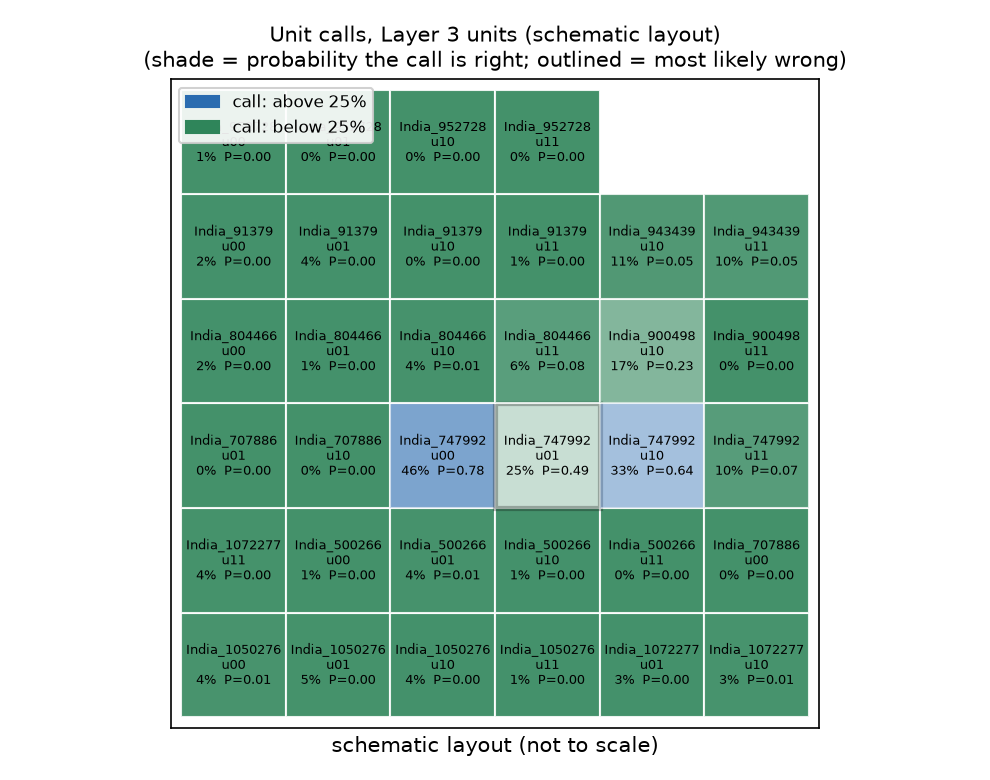

In [10]:
w = V.interactive_wizard(units1, event_html, lambda uid, tau: C.card_html(make_card(uid, units1, synced, tau)), TAU)
if w is not None:
    display(w)
display(HTML(V.static_wizard(event_html, table1, None, C.card_html(card1))))
display(Image(str(OUT / "unit_map.png"), width=480))

## 9 Artifacts

Written to `artifacts/layer5/`: `unit_calls.parquet` and `.csv` (after the demo sync),
`card_<unit>.json` and `.html`, `unit_map.png`, `unit_map.html`, `route_view.png`,
`field_checks_synced.csv`, `cross_check.json`, and `MANIFEST.json` with schema, shapes, seed,
provenance and hashes of the inputs and the code.

In [11]:
def sha(p):
    return hashlib.sha256(pathlib.Path(p).read_bytes()).hexdigest()[:16]

table1.to_parquet(OUT / "unit_calls.parquet", index=False)
table1.to_csv(OUT / "unit_calls.csv", index=False)
cards = {uid: make_card(uid, units1, synced) for uid in units1.unit_id}
for uid in (focus,):
    (OUT / f"card_{uid}.json").write_text(json.dumps(cards[uid], indent=1, default=str))
    (OUT / f"card_{uid}.html").write_text("<!doctype html><meta charset='utf-8'><title>Paddybird card</title>" + C.card_html(cards[uid]), encoding="utf-8")
(OUT / "receipts.json").write_text(json.dumps({u: c["receipt"] for u, c in cards.items()}, indent=1, default=str))
synced.to_csv(OUT / "field_checks_synced.csv", index=False)
(OUT / "cross_check.json").write_text(json.dumps(xc.to_dict("records"), indent=1, default=str))

inputs = {}
for L in ("layer1", "layer2", "layer3", "layer4"):
    d = ART / L
    for p in (sorted(d.rglob("*")) if d.exists() else []):
        if p.is_file() and p.stat().st_size < 200_000_000:
            inputs[p.relative_to(ART).as_posix()] = sha(p)
code_h = {f"paddybird/{n}": sha(ROOT / "paddybird" / n) for n in ("intake.py", "card.py", "views.py")}
files = {p.name: dict(sha256_16=sha(p), bytes=p.stat().st_size) for p in sorted(OUT.glob("*")) if p.is_file() and p.name != "MANIFEST.json"}
manifest = dict(layer=5, notebook="05_tool.ipynb", seed=SEED, tau=TAU, provenance=inp.provenance,
                fixture="paddybird.intake.make_fixture(seed=0); see its docstring" if not all(REAL.values()) else None,
                demo_entries="field checks and farmer reports in this run are typed demonstration entries, not field data",
                schema={"unit_calls.parquet": "rank, unit_id, name, theta, s, call (above|below), P_u, p_call_right, n_checks, p_wrong",
                        "card_<unit>.json": "unit_id, call, tau, theta, s, range95, P_u, p_call_right, n_checks, scenes[{id,date,sensor}], receipt{schema,inputs,output,output_hash,receipt_id}",
                        "receipts.json": "{unit_id: receipt}",
                        "field_checks_synced.csv": "unit_id, stratum, flooded, pi, officer, ts, [plot_id, entry_hash]",
                        "cross_check.json": "[{report_hash, unit_id, claim, unit_call, unit_P_u, p_flooded_used, consistent_prob, lean, weight, within_72h, inspect_priority}]"},
                shapes=dict(units=len(units1), checks=len(synced), routes=len(inp.routes), reports=len(xc)),
                versions=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__),
                inputs_sha256_16=inputs, code_sha256_16=code_h, files=files)
(OUT / "MANIFEST.json").write_text(json.dumps(manifest, indent=1, default=str))
print("wrote", len(files) + 1, "files to", OUT.relative_to(ROOT))

wrote 17 files to artifacts\layer5


## 10 Checks

Bounds stated in advance:
1. units without a call: 0 (every call is above or below; no abstain field anywhere in a card);
2. every P_u is in [0, 1] and every receipt re-derives (100 percent);
3. re-building a card from the same inputs gives the same receipt ID;
4. the duplicate queue entry is not double counted (exactly 3 new checks);
5. every cross-check has one of the two leans;
6. the route view has a flooded flag on every road (and, on the fixture lattice, at least one flooded
   road drawn in blue), and the manifest exists.

In [12]:
no_call = int((~table1.call.isin(C.CALLS)).sum())
assert no_call == 0, no_call
assert all("abstain" not in json.dumps(c).lower() for c in cards.values())
assert table1.P_u.between(0, 1).all() and table1.P_u.notna().all()
assert all(C.verify_receipt(c["receipt"]) for c in cards.values())
assert make_card(focus, units1, synced)["receipt_id"] == cards[focus]["receipt_id"]
assert len(new) == 3 and int(units1.set_index("unit_id").at[focus, "n_checks"]) == int(inp.units.set_index("unit_id").at[focus, "n_checks"]) + 3
assert set(xc.lean) <= {"consistent with radar", "inconsistent with radar"}
assert "flooded" in inp.roads_edges.columns
if not inp.provenance["roads"].startswith("real"):
    assert int(inp.roads_edges.flooded.sum()) > 0
assert (OUT / "MANIFEST.json").exists()
print(f"all layer 5 checks passed: {len(units1)} units, 0 without a call, {len(cards)} receipts verified; "
      f"real parts: {[k for k, v in REAL.items() if v] or 'none (fixture)'}")

all layer 5 checks passed: 34 units, 0 without a call, 34 receipts verified; real parts: ['units', 'scenes']
